In [1]:
#improt and load the dataset

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

raw_df = pd.read_csv("data/raw_quiz_responses.csv")
print("Raw shape:", raw_df.shape)
raw_df.head(10)

Raw shape: (4008, 6)


,student_id,question_id,topic,correct_option,selected_option,is_correct
0,STU_001,Q01,Algebra,D,D,1.0
1,STU_002,Q01,Algebra,D,D,1.0
2,STU_003,Q01,Algebra,D,D,1.0
3,STU_004,Q01,Algebra,D,D,1.0
4,STU_005,Q01,Algebra,D,D,1.0
5,STU_006,Q01,Algebra,D,D,1.0
6,STU_007,Q01,Algebra,D,D,1.0
7,STU_008,Q01,Algebra,D,D,1.0
8,STU_009,Q01,Algebra,D,D,1.0
9,STU_010,Q01,Algebra,D,A,0.0


In [3]:
#data audit and cleaning

In [4]:
# 1. Check duplicates
dup_count = raw_df.duplicated(subset=["student_id", "question_id"]).sum()
print(f"Duplicate (student_id, question_id) records found: {dup_count}")

clean_df = raw_df.drop_duplicates(subset=["student_id", "question_id"]).copy()

# 2. Audit missing responses
missing_summary = (
    clean_df.groupby("question_id")["is_correct"]
    .apply(lambda s: s.isna().sum())
    .reset_index(name="missing_count")
)
print("\nQuestions with highest missing responses:")
print(missing_summary.sort_values("missing_count", ascending=False).head(5))

# 3. Documented Cleaning Decision:
# Keep `is_correct` (NaN preserved) for attempt-based difficulty,
# and create `scored_correct` (NaN -> 0) for total student test score calculation.
clean_df["is_attempted"] = clean_df["is_correct"].notna().astype(int)
clean_df["scored_correct"] = clean_df["is_correct"].fillna(0).astype(int)

# Validate values
assert set(clean_df["scored_correct"].unique()).issubset({0, 1}), "Invalid score values!"
clean_df.to_csv("data/cleaned_quiz_responses.csv", index=False)
print("\nCleaned shape:", clean_df.shape)

Duplicate (student_id, question_id) records found: 8

Questions with highest missing responses:
   question_id  missing_count
19         Q20             15
18         Q19             13
14         Q15             13
15         Q16             13
16         Q17             11

Cleaned shape: (4000, 8)


In [5]:
# item difficulty

In [6]:
def compute_item_difficulty(df: pd.DataFrame) -> pd.DataFrame:
    """
    Computes two difficulty metrics per question:
    - p_attempted: proportion correct among students who answered (excludes blanks)
    - p_total: proportion correct across all enrolled students (blanks treated as 0)
    """
    grouped = df.groupby(["question_id", "topic"], as_index=False).agg(
        total_students=("student_id", "nunique"),
        attempted_count=("is_attempted", "sum"),
        correct_count=("scored_correct", "sum"),
    )
    grouped["missing_count"] = grouped["total_students"] - grouped["attempted_count"]
    grouped["missing_rate"] = (grouped["missing_count"] / grouped["total_students"]).round(3)
    grouped["p_attempted"] = (grouped["correct_count"] / grouped["attempted_count"]).round(3)
    grouped["p_total"] = (grouped["correct_count"] / grouped["total_students"]).round(3)

    def label_difficulty(p: float) -> str:
        if p > 0.85:
            return "Very Easy"
        elif p >= 0.60:
            return "Moderate-Easy"
        elif p >= 0.30:
            return "Moderate-Hard"
        else:
            return "Very Hard"

    grouped["difficulty_band"] = grouped["p_attempted"].apply(label_difficulty)
    return grouped

difficulty_df = compute_item_difficulty(clean_df)
difficulty_df.head(10)

,question_id,topic,total_students,attempted_count,correct_count,missing_count,missing_rate,p_attempted,p_total,difficulty_band
0,Q01,Algebra,200,198,184,2,0.010,0.929,0.920,Very Easy
1,Q02,Algebra,200,197,110,3,0.015,0.558,0.550,Moderate-Hard
2,Q03,Algebra,200,196,165,4,0.020,0.842,0.825,Moderate-Easy
3,Q04,Algebra,200,198,76,2,0.010,0.384,0.380,Moderate-Hard
4,Q05,Algebra,200,198,92,2,0.010,0.465,0.460,Moderate-Hard
5,Q06,Geometry,200,198,144,2,0.010,0.727,0.720,Moderate-Easy
6,Q07,Geometry,200,196,103,4,0.020,0.526,0.515,Moderate-Hard
7,Q08,Geometry,200,196,95,4,0.020,0.485,0.475,Moderate-Hard
8,Q09,Geometry,200,199,96,1,0.005,0.482,0.480,Moderate-Hard
9,Q10,Geometry,200,197,107,3,0.015,0.543,0.535,Moderate-Hard


In [7]:
# discrimination indicator

In [8]:
def compute_discrimination_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """
    Computes two standard item discrimination indicators:
    1. Upper-Lower Discrimination Index (D): P_upper(top 27%) - P_lower(bottom 27%)
    2. Corrected Item-Total Correlation (r_pb): correlation between item score
       and student's total score on ALL OTHER items (avoids self-inflation).
    """
    # Pivot to student x question score matrix
    score_matrix = df.pivot(
        index="student_id", columns="question_id", values="scored_correct"
    )
    total_scores = score_matrix.sum(axis=1)

    # Top 27% and Bottom 27% student cohorts
    n_students = len(score_matrix)
    k = max(1, int(round(0.27 * n_students)))
    ranked_students = total_scores.sort_values(ascending=False).index
    upper_ids = ranked_students[:k]
    lower_ids = ranked_students[-k:]

    rows = []
    for q_id in score_matrix.columns:
        item_scores = score_matrix[q_id]
        rest_scores = total_scores - item_scores

        p_upper = item_scores.loc[upper_ids].mean()
        p_lower = item_scores.loc[lower_ids].mean()
        disc_index = p_upper - p_lower

        # Point-biserial correlation with rest-of-test score
        if item_scores.std() == 0 or rest_scores.std() == 0:
            item_total_r = np.nan
        else:
            item_total_r = item_scores.corr(rest_scores)

        rows.append(
            {
                "question_id": q_id,
                "p_upper_27": round(p_upper, 3),
                "p_lower_27": round(p_lower, 3),
                "discrimination_D": round(disc_index, 3),
                "item_total_corr": round(item_total_r, 3),
            }
        )

    return pd.DataFrame(rows)

disc_df = compute_discrimination_metrics(clean_df)
item_metrics = pd.merge(difficulty_df, disc_df, on="question_id")
item_metrics

,question_id,topic,total_students,attempted_count,correct_count,missing_count,missing_rate,p_attempted,p_total,difficulty_band,p_upper_27,p_lower_27,discrimination_D,item_total_corr
0,Q01,Algebra,200,198,184,2,0.010,0.929,0.920,Very Easy,0.926,0.815,0.111,0.073
1,Q02,Algebra,200,197,110,3,0.015,0.558,0.550,Moderate-Hard,0.889,0.278,0.611,0.315
2,Q03,Algebra,200,196,165,4,0.020,0.842,0.825,Moderate-Easy,0.963,0.667,0.296,0.234
3,Q04,Algebra,200,198,76,2,0.010,0.384,0.380,Moderate-Hard,0.611,0.167,0.444,0.189
4,Q05,Algebra,200,198,92,2,0.010,0.465,0.460,Moderate-Hard,0.648,0.241,0.407,0.189
5,Q06,Geometry,200,198,144,2,0.010,0.727,0.720,Moderate-Easy,0.815,0.463,0.352,0.145
6,Q07,Geometry,200,196,103,4,0.020,0.526,0.515,Moderate-Hard,0.759,0.296,0.463,0.274
7,Q08,Geometry,200,196,95,4,0.020,0.485,0.475,Moderate-Hard,0.648,0.315,0.333,0.192
8,Q09,Geometry,200,199,96,1,0.005,0.482,0.480,Moderate-Hard,0.778,0.222,0.556,0.244
9,Q10,Geometry,200,197,107,3,0.015,0.543,0.535,Moderate-Hard,0.833,0.241,0.593,0.360


In [9]:
# AI feature

In [10]:
def ai_item_review_assistant(metrics_df: pd.DataFrame) -> pd.DataFrame:
    """
    Rule-based AI Item-Review Assistant:
    Applies rubric checks and quality thresholds to flag items with high
    wrong-answer rates, poor discrimination, or high missingness for teacher review.
    """
    reviewed = metrics_df.copy()
    flags = []
    recommendations = []
    uncertainties = []

    for _, row in reviewed.iterrows():
        item_flags = []
        notes = []

        # Rule 1: High wrong-answer rate (low difficulty index)
        if row["p_attempted"] < 0.30:
            item_flags.append("HIGH_WRONG_RATE")
            notes.append(
                f"Only {row['p_attempted']*100:.1f}% answered correctly; check wording or curriculum alignment."
            )
        elif row["p_attempted"] > 0.90:
            item_flags.append("CEILING_EFFECT")
            notes.append(
                f"{row['p_attempted']*100:.1f}% answered correctly; item may be too easy to differentiate mastery."
            )

        # Rule 2: Discrimination thresholds
        if row["discrimination_D"] < 0 or row["item_total_corr"] < 0:
            item_flags.append("NEGATIVE_DISCRIMINATION")
            notes.append(
                "Lower-scoring students outperformed higher-scoring students; inspect answer key and distractors immediately."
            )
        elif row["discrimination_D"] < 0.20 or row["item_total_corr"] < 0.15:
            item_flags.append("LOW_DISCRIMINATION")
            notes.append(
                "Weak separation between high and low performers; review distractor plausibility."
            )

        # Rule 3: Missing response threshold
        if row["missing_rate"] >= 0.04:
            item_flags.append("ELEVATED_OMISSION")
            notes.append(
                f"{row['missing_rate']*100:.1f}% skipped this item; check test fatigue or unclear prompt."
            )

        if not item_flags:
            flags.append("OK")
            recommendations.append("Retain item; metrics fall within acceptable pedagogical thresholds.")
        else:
            flags.append(" | ".join(item_flags))
            recommendations.append(" ".join(notes))

        # Explicit uncertainty note (required by rubric)
        uncertainties.append(
            f"Based on N={row['attempted_count']} attempts; guessing (~25% on 4-option MCQ) & topic difficulty may affect raw p."
        )

    reviewed["review_flags"] = flags
    reviewed["assistant_suggestion"] = recommendations
    reviewed["uncertainty_note"] = uncertainties
    reviewed["human_verified_status"] = "Pending Teacher Inspection"
    return reviewed

review_report = ai_item_review_assistant(item_metrics)
review_report.to_csv("outputs/item_review_report.csv", index=False)

# Display flagged items
flagged_items = review_report[review_report["review_flags"] != "OK"]
print(f"Flagged {len(flagged_items)} out of {len(review_report)} questions for teacher review:\n")
flagged_items[["question_id", "topic", "p_attempted", "discrimination_D", "item_total_corr", "review_flags"]]

Flagged 10 out of 20 questions for teacher review:



,question_id,topic,p_attempted,discrimination_D,item_total_corr,review_flags
0,Q01,Algebra,0.929,0.111,0.073,CEILING_EFFECT | LOW_DISCRIMINATION
5,Q06,Geometry,0.727,0.352,0.145,LOW_DISCRIMINATION
10,Q11,Statistics,0.723,0.278,0.119,LOW_DISCRIMINATION
11,Q12,Statistics,0.613,0.130,-0.003,NEGATIVE_DISCRIMINATION
14,Q15,Statistics,0.642,-0.148,-0.264,NEGATIVE_DISCRIMINATION | ELEVATED_OMISSION
15,Q16,Logic & Word Problems,0.497,0.704,0.384,ELEVATED_OMISSION
16,Q17,Logic & Word Problems,0.778,0.352,0.202,ELEVATED_OMISSION
17,Q18,Logic & Word Problems,0.295,0.315,0.177,HIGH_WRONG_RATE
18,Q19,Logic & Word Problems,0.422,0.574,0.317,ELEVATED_OMISSION
19,Q20,Logic & Word Problems,0.773,0.389,0.238,ELEVATED_OMISSION


In [11]:
#visualizations

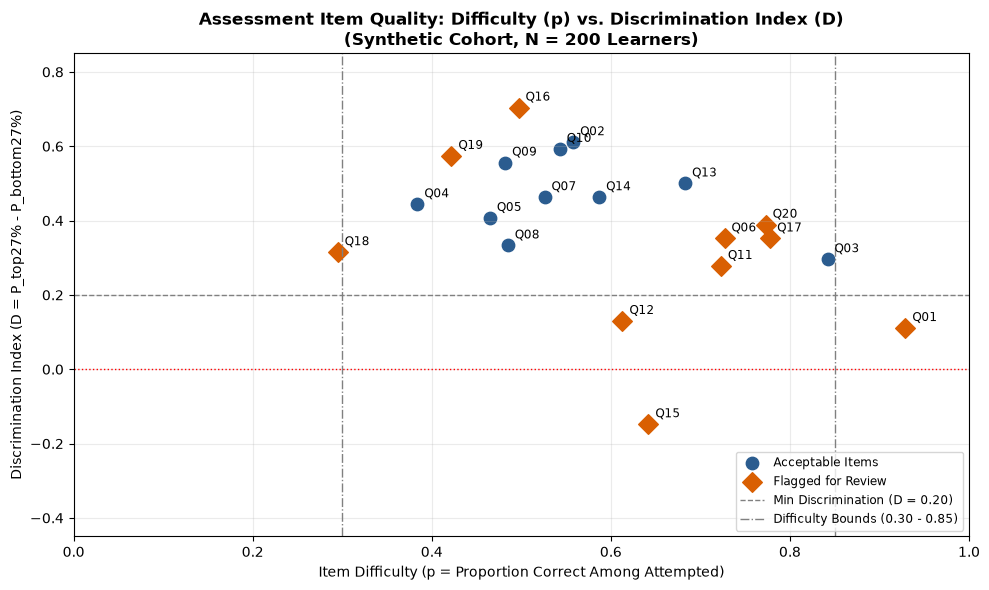

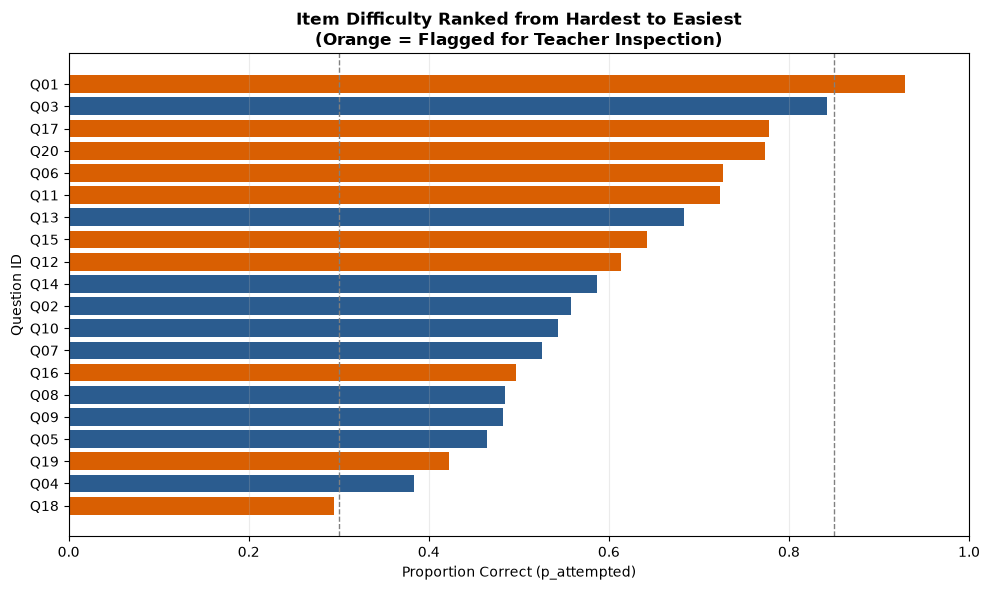

In [12]:
# Chart 1: Difficulty vs. Discrimination Quadrant Plot
fig, ax = plt.subplots(figsize=(10, 6))

is_flagged = review_report["review_flags"] != "OK"
ax.scatter(
    review_report.loc[~is_flagged, "p_attempted"],
    review_report.loc[~is_flagged, "discrimination_D"],
    color="#2b5c8f",
    s=80,
    label="Acceptable Items",
)
ax.scatter(
    review_report.loc[is_flagged, "p_attempted"],
    review_report.loc[is_flagged, "discrimination_D"],
    color="#d95f02",
    s=100,
    marker="D",
    label="Flagged for Review",
)

for _, r in review_report.iterrows():
    ax.annotate(
        r["question_id"],
        (r["p_attempted"], r["discrimination_D"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8.5,
    )

# Threshold reference lines
ax.axhline(0.20, color="gray", linestyle="--", linewidth=1, label="Min Discrimination (D = 0.20)")
ax.axhline(0.00, color="red", linestyle=":", linewidth=1)
ax.axvline(0.30, color="gray", linestyle="-.", linewidth=1, label="Difficulty Bounds (0.30 - 0.85)")
ax.axvline(0.85, color="gray", linestyle="-.", linewidth=1)

ax.set_xlim(0.0, 1.0)
ax.set_ylim(-0.45, 0.85)
ax.set_title("Assessment Item Quality: Difficulty (p) vs. Discrimination Index (D)\n(Synthetic Cohort, N = 200 Learners)", fontsize=12, fontweight="bold")
ax.set_xlabel("Item Difficulty (p = Proportion Correct Among Attempted)")
ax.set_ylabel("Discrimination Index (D = P_top27% - P_bottom27%)")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("outputs/difficulty_vs_discrimination.png", dpi=200)
plt.show()

# Chart 2: Ranked Item Difficulty Bar Chart
sorted_items = review_report.sort_values("p_attempted", ascending=True)
colors = ["#d95f02" if f != "OK" else "#2b5c8f" for f in sorted_items["review_flags"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(sorted_items["question_id"], sorted_items["p_attempted"], color=colors)
ax.axvline(0.30, color="gray", linestyle="--", linewidth=1)
ax.axvline(0.85, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0.0, 1.0)
ax.set_title("Item Difficulty Ranked from Hardest to Easiest\n(Orange = Flagged for Teacher Inspection)", fontsize=12, fontweight="bold")
ax.set_xlabel("Proportion Correct (p_attempted)")
ax.set_ylabel("Question ID")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig("outputs/item_difficulty_overview.png", dpi=200)
plt.show()

In [13]:
# verification and distractor

In [14]:
# Inspect distractor choices on flagged items (e.g., Q15 and Q18) to verify why they failed
for q_target in ["Q15", "Q18"]:
    sub = clean_df[clean_df["question_id"] == q_target]
    correct_key = sub["correct_option"].iloc[0]
    dist_counts = sub["selected_option"].value_counts(dropna=False, normalize=True).round(3)
    print(f"--- Verification Audit for {q_target} (Correct Key: {correct_key}) ---")
    print(dist_counts)
    print()

--- Verification Audit for Q15 (Correct Key: D) ---
selected_option
D      0.600
A      0.125
B      0.120
C      0.090
NaN    0.065
Name: proportion, dtype: float64

--- Verification Audit for Q18 (Correct Key: A) ---
selected_option
A      0.285
B      0.270
D      0.205
C      0.205
NaN    0.035
Name: proportion, dtype: float64

